# Figure S10: Enamine Score Threshold

Visualizes the score distribution of the top 200k Enamine compounds ranked by PhenoCompass mTOR/AKT/PI3K score, highlighting the PI3K drug recall threshold.

This notebook generates:
1. Scatter plot of top 200k Enamine compound scores ranked by PhenoCompass mTOR/AKT/PI3K score, with PI3K drug recall threshold

## 1. Setup and Configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt

import phenocompass
sys.path.insert(0, os.path.join(os.path.dirname(phenocompass.__file__), "..", "..", "notebooks"))
from utils import setup_publication_style, save_figure, save_figure_data, REPO_ROOT

%matplotlib inline

BASE_DIR = str(REPO_ROOT)
setup_publication_style(BASE_DIR)

# --- Output directories ---
DATA_DIR = os.path.join(BASE_DIR, "data", "enamine_score_threshold")
FIGURE_DIR = os.path.join(BASE_DIR, "figures", "enamine_score_threshold")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

FINAL_DATA_DIR = os.path.join(BASE_DIR, "final_data")

FORCE_RECOMPUTE = False

print("Figures will be saved to figures/")
print("Intermediate data will be saved to data/")

No normalization for SPS. Feature removed!


No normalization for AvgIpc. Feature removed!


Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'


Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'


Skipped loading some Jax models, missing a dependency. No module named 'haiku'


Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


Figures will be saved to figures/
Intermediate data will be saved to data/


## 2. Data Loading

In [2]:
enamine_df = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "enamine/enamine_predictions.parquet"))
min_enamine_score = enamine_df["score"].values.min()

pi3k_drugs_df = pd.read_csv(os.path.join(FINAL_DATA_DIR, "chembl_drugs/chembl_drugs.pi3k.tsv"),
                            sep="\t", index_col=0)

print(f"PI3K drugs: {len(pi3k_drugs_df)} rows")

scores_df = pd.read_parquet(os.path.join(FINAL_DATA_DIR, "enamine/pi3k_mtor_anchor_scores.top10M.parquet"))
print(f"Enamine ranked scores: {len(scores_df)} rows")

PI3K drugs: 55 rows


Enamine ranked scores: 9042534 rows


## 3. PI3K Drug Recall at Enamine Score Threshold

In [3]:
print("% Recall of All PI3K Drugs: {:.3f}".format(
    (pi3k_drugs_df["pi3k_score"].values > min_enamine_score).mean()
))

% Recall of All PI3K Drugs: 0.509


## 4. Score Rank Plot

Figure already exists


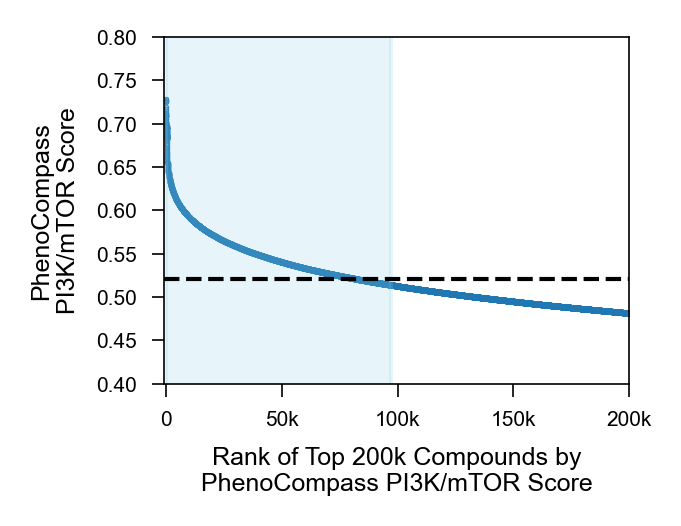

In [4]:
N = 200000

rank_idx = np.arange(0, 100).tolist() + np.arange(100, N, 20).tolist()
y_values = np.array(sorted(scores_df.iloc[0:N]["cluster3_scores"].values, reverse=True))[rank_idx]

plt.figure(figsize=(2, 1.5))
plt.scatter(rank_idx, y_values, s=0.1)
plt.fill_between(np.linspace(0, len(enamine_df), 10), 0, 1, color='skyblue', alpha=0.2)
plt.axhline(np.median(pi3k_drugs_df["pi3k_score"]),
            color="black", linestyle="--", linewidth=1)
plt.xlabel("Rank of Top 200k Compounds by\nPhenoCompass PI3K/mTOR Score")
plt.ylabel("PhenoCompass\nPI3K/mTOR Score")
plt.xticks([0, 50000, 100000, 150000, 200000], ["0", "50k", "100k", "150k", "200k"])
plt.ylim([0.4, 0.8])
plt.xlim([-1000, 200000])

fig_path = os.path.join(FIGURE_DIR, "FigS10_enamine_scores_rank.pdf")
save_figure(fig_path, FORCE_RECOMPUTE)
plt.show()

In [5]:
# Save figure source data for manuscript reproducibility
# Enamine score rank data for scatter plot
N = 200000
rank_idx = np.arange(0, 100).tolist() + np.arange(100, N, 20).tolist()
scores_sorted = np.array(sorted(scores_df.iloc[0:N]["cluster3_scores"].values, reverse=True))

enamine_rank_df = pd.DataFrame({
    "rank": rank_idx,
    "score": scores_sorted[rank_idx],
    "pi3k_drug_threshold": np.percentile(pi3k_drugs_df["pi3k_score"], 50)
})

fig_data_path = os.path.join(FIGURE_DIR, "FigS10_enamine_scores_rank_data.tsv")
save_figure_data(enamine_rank_df, fig_data_path, FORCE_RECOMPUTE)

Figure data already exists
